# ĐỒ ÁN MACHINE LEARNING: DỰ BÁO LƯỢT XEM SẢN PHẨM THEO NGÀY
**Tập dữ liệu:** Clickstream E-Shop Clothing 2008 (UCI Repository)

**Trình tự làm bài của nhóm:**
1. Đọc dữ liệu & khám phá sơ bộ
2. Kiểm tra chất lượng & làm sạch dữ liệu
3. Vì sao không dự đoán `price2` như nhiều bài trên mạng → chọn bài toán của nhóm
4. Xây bảng (sản phẩm × ngày), khám phá biến mục tiêu, tạo đặc trưng từ quá khứ
5. Mã hóa One-Hot & chia Train / Validation / Test theo thời gian
6. Baseline và các mô hình hồi quy (Linear Regression, Ridge, KNN, Decision Tree, Random Forest) — chọn siêu tham số trên Validation
7. Huấn luyện lại & đánh giá một lần trên Test
8. Phân tích kết quả
9. Góc nhìn khác: đặt bài toán dạng phân loại (Logistic Regression, Naive Bayes, KNN, Decision Tree, Random Forest)
10. Kết luận

---
## PHẦN 1: ĐỌC DỮ LIỆU & KHÁM PHÁ SƠ BỘ
Đầu tiên, nhóm nạp dữ liệu từ file CSV và xem 5 dòng đầu tiên để nắm cấu trúc bảng.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv('e-shop-clothing-2008.csv', sep=';')
df.head()

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


**Nhận xét 1:** Tên gốc của một số cột khá dài (như `page 1 (main category)`, `page 2 (clothing model)`). Nhóm đổi lại tên cột ngắn gọn (giữ đúng thứ tự cột gốc) và dùng `df.info()` để kiểm tra kiểu dữ liệu.

In [ ]:
df.columns = ['year', 'month', 'day', 'order', 'country', 'session',
              'category', 'product', 'colour', 'location', 'photo', 'price', 'price2', 'page']

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   year      165474 non-null  int64 
 1   month     165474 non-null  int64 
 2   day       165474 non-null  int64 
 3   order     165474 non-null  int64 
 4   country   165474 non-null  int64 
 5   session   165474 non-null  int64 
 6   category  165474 non-null  int64 
 7   product   165474 non-null  object
 8   colour    165474 non-null  int64 
 9   location  165474 non-null  int64 
 10  photo     165474 non-null  int64 
 11  price     165474 non-null  int64 
 12  price2    165474 non-null  int64 
 13  page      165474 non-null  int64 
dtypes: int64(13), object(1)
memory usage: 17.7+ MB


**Nhận xét 2:** Bảng gồm 165.474 dòng và 14 cột. Chỉ cột `product` là chữ (mã sản phẩm như `A13`), các cột còn lại là số nguyên. Tiếp theo, nhóm kiểm tra giá trị bị thiếu (`isnull`) và dòng bị trùng lặp hoàn toàn (`duplicated`).

In [ ]:
print('Số giá trị bị thiếu (NaN) ở từng cột:')
print(df.isnull().sum())

print('\nSố dòng bị trùng lặp hoàn toàn:', df.duplicated().sum())

Số giá trị bị thiếu (NaN) ở từng cột:
year        0
month       0
day         0
order       0
country     0
session     0
category    0
product     0
colour      0
location    0
photo       0
price       0
price2      0
page        0
dtype: int64

Số dòng bị trùng lặp hoàn toàn: 0


**Nhận xét 3:** Không có giá trị bị thiếu và không có dòng trùng. Nhóm dùng `df.describe()` để xem phân phối thống kê của các biến số.

In [ ]:
df.describe()

,year,month,day,order,country,session,category,colour,location,photo,price,price2,page
count,165474.0,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000
mean,2008.0,5.585887,14.524554,9.817476,26.952621,12058.417056,2.400842,6.227655,3.258198,1.260071,43.802507,1.488167,1.710166
std,0.0,1.328160,8.830374,13.478411,7.150691,7008.418903,1.144420,4.235606,1.713206,0.438674,12.548131,0.499861,0.982412
min,2008.0,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,18.000000,1.000000,1.000000
25%,2008.0,4.000000,7.000000,2.000000,29.000000,5931.000000,1.000000,3.000000,2.000000,1.000000,33.000000,1.000000,1.000000
50%,2008.0,5.000000,14.000000,6.000000,29.000000,11967.500000,2.000000,4.000000,3.000000,1.000000,43.000000,1.000000,1.000000
75%,2008.0,7.000000,22.000000,12.000000,29.000000,18219.000000,3.000000,9.000000,5.000000,2.000000,52.000000,2.000000,2.000000
max,2008.0,8.000000,31.000000,195.000000,47.000000,24026.000000,4.000000,14.000000,6.000000,2.000000,82.000000,2.000000,5.000000


**Câu hỏi quan trọng: một dòng dữ liệu thể hiện điều gì?** Nhóm xem thử toàn bộ các dòng của phiên truy cập (session) số 1.

In [ ]:
print('Số sản phẩm khác nhau     :', df['product'].nunique())
print('Số phiên truy cập (session):', df['session'].nunique())

# Có gì trong session 1?
df[df['session'] == 1]

Số sản phẩm khác nhau     : 217
Số phiên truy cập (session): 24026


,year,month,day,order,country,session,category,product,colour,location,photo,price,price2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1
5,2008,4,1,6,29,1,3,C56,6,1,2,57,1,4
6,2008,4,1,7,29,1,3,C57,5,1,2,33,2,4
7,2008,4,1,8,29,1,4,P67,9,5,1,38,1,4
8,2008,4,1,9,29,1,4,P82,6,4,2,48,1,5


**Nhận xét 4:** Session 1 có 9 dòng, cột `order` chạy từ 1 đến 9 → **mỗi dòng là một lần khách bấm xem một sản phẩm** (dữ liệu clickstream). Dữ liệu **không có thông tin mua hàng**, nên nhóm không thể dự đoán doanh số; thứ có thể đếm được là **số lượt xem**.

---
## PHẦN 2: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU & LÀM SẠCH TỪNG BƯỚC
Ba cột `year`, `month`, `day` thể hiện thời gian. Nhóm ghép thành cột `date` để kiểm tra tính liên tục của dữ liệu theo ngày.

In [ ]:
df['date'] = pd.to_datetime(df[['year', 'month', 'day']])

print('Ngày bắt đầu:', df['date'].min().date())
print('Ngày kết thúc:', df['date'].max().date())
print('Tổng số ngày thu thập:', df['date'].nunique())

# Kiểm tra có ngày nào bị thiếu hẳn trên lịch không
all_days = pd.date_range(df['date'].min(), df['date'].max())
print('Số ngày trên lịch:', len(all_days), '| Số ngày bị thiếu:', len(all_days) - df['date'].nunique())

Ngày bắt đầu: 2008-04-01
Ngày kết thúc: 2008-08-13
Tổng số ngày thu thập: 135
Số ngày trên lịch: 135 | Số ngày bị thiếu: 0


Tiếp theo, nhóm vẽ tổng số lượt click của toàn cửa hàng theo từng ngày để xem có ngày nào bất thường không.

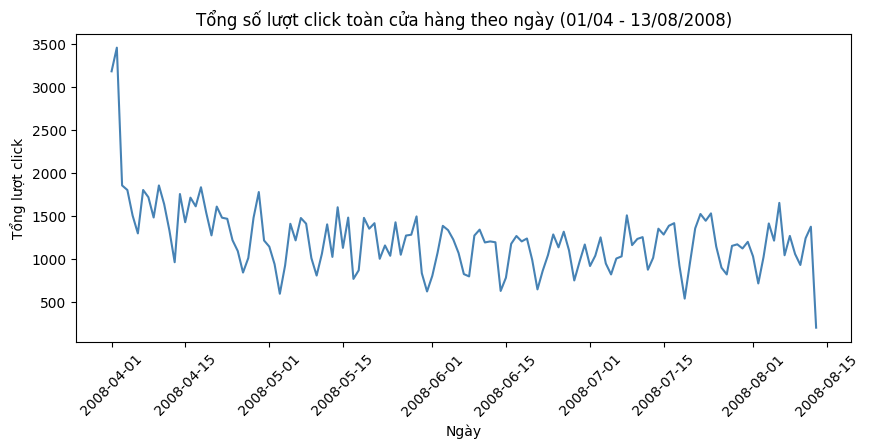

Trung vị số click mỗi ngày: 1203.0

Số lượt click trong 5 ngày cuối cùng:
date
2008-08-09    1056
2008-08-10     929
2008-08-11    1240
2008-08-12    1374
2008-08-13     200
dtype: int64


In [ ]:
daily_total = df.groupby('date').size()

plt.figure(figsize=(10, 4))
plt.plot(daily_total.index, daily_total.values, color='steelblue')
plt.title('Tổng số lượt click toàn cửa hàng theo ngày (01/04 - 13/08/2008)')
plt.xlabel('Ngày')
plt.ylabel('Tổng lượt click')
plt.xticks(rotation=45)
plt.show()

print('Trung vị số click mỗi ngày:', daily_total.median())
print('\nSố lượt click trong 5 ngày cuối cùng:')
print(daily_total.tail(5))

**Phát hiện bất thường 1:** Ngày cuối cùng (`2008-08-13`) chỉ có **200 lượt click**, bằng khoảng 17% mức trung vị (~1.200 click/ngày). Đây là ngày cuối của file log, nên khả năng cao hệ thống dừng ghi log giữa ngày. Giữ ngày này sẽ làm sai việc đánh giá mô hình, nên nhóm loại bỏ ngày `2008-08-13`.

In [ ]:
df = df[df['date'] < '2008-08-13'].copy()
print('Số dòng còn lại sau khi loại bỏ ngày 13/08:', len(df))

Số dòng còn lại sau khi loại bỏ ngày 13/08: 165274


**Kiểm tra tính nhất quán của sản phẩm:** Theo tài liệu mô tả, cửa hàng có **217 mã sản phẩm**. Nhóm kiểm tra xem trong suốt 5 tháng, mỗi sản phẩm có giữ cố định các thuộc tính hay không.

In [ ]:
for col in ['category', 'colour', 'location', 'photo', 'price', 'price2', 'page']:
    check = df.groupby('product')[col].nunique()
    print(f'Số sản phẩm có nhiều hơn 1 giá trị ở cột {col}: {(check > 1).sum()}')

Số sản phẩm có nhiều hơn 1 giá trị ở cột category: 1
Số sản phẩm có nhiều hơn 1 giá trị ở cột colour: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột location: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột photo: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột price: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột price2: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột page: 0


**Phát hiện bất thường 2:** Mọi thuộc tính đều cố định, **riêng cột `category` có 1 sản phẩm** xuất hiện ở 2 danh mục. Nhóm tìm sản phẩm đó.

In [ ]:
cat_per_prod = df.groupby('product')['category'].nunique()
print('Sản phẩm bị ghi vào nhiều danh mục:')
print(cat_per_prod[cat_per_prod > 1])

print('\nSố lần xuất hiện của mã A18 ở từng danh mục:')
print(df[df['product'] == 'A18']['category'].value_counts())

Sản phẩm bị ghi vào nhiều danh mục:
product
A18    2
Name: category, dtype: int64

Số lần xuất hiện của mã A18 ở từng danh mục:
category
1    935
2      1
Name: count, dtype: int64


A18 có 935 click ở danh mục 1 và chỉ 1 click ở danh mục 2. Để chắc chắn danh mục đúng, nhóm kiểm tra **chữ cái đầu của mã sản phẩm** có khớp với danh mục không.

In [ ]:
pd.crosstab(df['product'].str[0], df['category'])

category,1,2,3,4
product,,,,
A,49685,1,0,0
B,0,38378,0,0
C,0,0,38537,0
P,0,0,0,38673


**Nhận xét:** Mã bắt đầu bằng `A` → danh mục 1 (Trousers), `B` → 2 (Skirts), `C` → 3 (Blouses), `P` → 4 (Sale). Chỉ có đúng 1 dòng lệch quy luật (chính là click lỗi của A18) → nhóm sửa A18 về danh mục 1.

In [ ]:
df.loc[df['product'] == 'A18', 'category'] = 1
print('Số sản phẩm lỗi sau khi sửa:', (df.groupby('product')['category'].nunique() > 1).sum())

Số sản phẩm lỗi sau khi sửa: 0


---
## PHẦN 3: VÌ SAO CÁCH LÀM PHỔ BIẾN TRÊN MẠNG (DỰ ĐOÁN `PRICE2`) KHÔNG CÓ GIÁ TRỊ THỰC TẾ
Nhiều bài làm trên Kaggle/GitHub dùng tập dữ liệu này để phân loại cột `price2` (giá có cao hơn trung bình danh mục không) trên từng lượt click. Nhóm chạy 3 thử nghiệm để kiểm tra.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

y_click = (df['price2'] == 1).astype(int)

# TN1: Giữ cột 'price' trong tập đầu vào X
X_with_price = df[['category', 'colour', 'location', 'photo', 'price', 'page']]
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(
    X_with_price, y_click,
    test_size=0.2,
    random_state=42)
dt1 = DecisionTreeClassifier(max_depth=5, random_state=42)
dt1.fit(X_tr1, y_tr1)
print('1. Dự đoán price2 (giữ cột price) -> Accuracy:', round(accuracy_score(y_te1, dt1.predict(X_te1))*100, 2), '%')

# TN2: Bỏ cột 'price', chia train_test_split ngẫu nhiên theo dòng click
X_no_price = df[['category', 'colour', 'location', 'photo', 'page']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_no_price, y_click,
    test_size=0.2,
    random_state=42)
dt2 = DecisionTreeClassifier(random_state=42)
dt2.fit(X_tr2, y_tr2)
print('2. Dự đoán price2 (bỏ price, chia ngẫu nhiên) -> Accuracy:', round(accuracy_score(y_te2, dt2.predict(X_te2))*100, 2), '%')

1. Dự đoán price2 (giữ cột price) -> Accuracy: 100.0 %
2. Dự đoán price2 (bỏ price, chia ngẫu nhiên) -> Accuracy: 92.91 %


**Thử nghiệm 3:** Nếu mô hình thật sự "hiểu" thì nó phải đoán được `price2` cho **sản phẩm chưa từng thấy**. Nhóm chia 217 sản phẩm thành 5 nhóm (lấy xen kẽ theo thứ tự chữ cái bằng `products[i::5]`). Mỗi lần giấu hẳn 1 nhóm sản phẩm để kiểm tra và chỉ học trên 4 nhóm còn lại.

In [ ]:
products = sorted(df['product'].unique())
accuracies = []

for i in range(5):
    test_products = products[i::5]
    is_test = df['product'].isin(test_products)

    dt3 = DecisionTreeClassifier(random_state=42)
    dt3.fit(X_no_price[~is_test], y_click[~is_test])

    acc = accuracy_score(y_click[is_test], dt3.predict(X_no_price[is_test]))
    accuracies.append(acc)
    print('Lần', i + 1, '- số sản phẩm kiểm tra:', len(test_products), '- Accuracy:', round(acc * 100, 1), '%')

print('3. Accuracy trung bình với SẢN PHẨM MỚI:', round(np.mean(accuracies) * 100, 1), '%')
print('   Mốc "luôn đoán lớp phổ biến nhất":', round(max(y_click.mean(), 1 - y_click.mean()) * 100, 1), '%')

Lần 1 - số sản phẩm kiểm tra: 44 - Accuracy: 27.1 %
Lần 2 - số sản phẩm kiểm tra: 44 - Accuracy: 45.1 %
Lần 3 - số sản phẩm kiểm tra: 43 - Accuracy: 46.4 %
Lần 4 - số sản phẩm kiểm tra: 43 - Accuracy: 43.9 %
Lần 5 - số sản phẩm kiểm tra: 43 - Accuracy: 57.8 %
3. Accuracy trung bình với SẢN PHẨM MỚI: 44.1 %
   Mốc "luôn đoán lớp phổ biến nhất": 51.2 %


**Kết luận từ thực nghiệm:**
1. Giữ `price` → **100%**, vì `price2` được tính trực tiếp từ `price` (giá > giá trung bình danh mục). Đây là **target leakage**: đầu vào chứa sẵn đáp án.
2. Bỏ `price` nhưng chia ngẫu nhiên → **~93%**, vì cả cửa hàng chỉ có 217 sản phẩm với thuộc tính cố định. Cùng một sản phẩm nằm ở cả Train và Test, nên mô hình chỉ **học thuộc** bảng 217 sản phẩm.
3. Với sản phẩm mới → **~44%**, còn thấp hơn cả mốc "luôn đoán lớp phổ biến nhất" (~51%). Điểm cao ở thử nghiệm 2 là ảo.
4. Ngoài ra, giá của sản phẩm cửa hàng đã biết sẵn, nên dự đoán `price2` không giúp được quyết định kinh doanh nào.

**Bài toán của nhóm:** Dự báo **số lượt xem của từng sản phẩm trong ngày mai**, chỉ dùng thông tin đến hết hôm nay → hỗ trợ **vận hành hằng ngày**: chọn sản phẩm nổi bật, phân bổ quảng cáo, theo dõi sản phẩm đang tăng/giảm độ quan tâm. (Việc nhập hàng cần dự báo xa hơn, ví dụ tổng 7 ngày tới — nhóm để ở hướng cải thiện.) Đây là bài toán **hồi quy (regression)** có yếu tố **chuỗi thời gian**.

**Nhóm đã cân nhắc nhiều cách đặt bài toán trước khi chọn:**

| Cách đặt bài toán | Quyết định | Lý do |
|---|---|---|
| Phân loại `price2` cho từng click | Loại | Leakage / học thuộc, không có giá trị kinh doanh (3 thử nghiệm ở trên) |
| **Hồi quy: lượt xem ngày mai của từng sản phẩm** | **Chọn làm bài chính** | Đầu ra là con số, chứa nhiều thông tin nhất, dùng được cho nhiều quyết định |
| Phân loại: ngày mai sản phẩm có được "quan tâm cao" không | Làm thêm ở Phần 9 để so sánh | Câu hỏi có/không dễ dùng cho việc chọn sản phẩm nổi bật; cho phép dùng Logistic Regression và Naive Bayes |
| Mỗi sản phẩm một mô hình riêng | Không chọn | Mỗi sản phẩm chỉ có ~100 ngày dữ liệu; một mô hình chung học được quy luật chung từ cả 217 sản phẩm |
| Dự báo theo từng phiên truy cập / quốc gia | Không chọn | Quyết định kinh doanh được đưa ra theo sản phẩm và theo ngày; ~80% click đến từ Ba Lan nên chia theo quốc gia rất thưa |

**Chọn thuật toán nào trong các thuật toán đã học?**

| Thuật toán đã học | Dùng cho | Có phù hợp với bài chính (hồi quy)? | Dùng ở đâu |
|---|---|---|---|
| Linear Regression | Hồi quy | Có — mô hình nền, dễ giải thích | Phần 6 |
| Ridge (Linear Regression có phạt) | Hồi quy | Có — kiểm tra đa cộng tuyến giữa các cột trung bình | Phần 6 |
| KNN | Hồi quy và phân loại | Có (`KNeighborsRegressor`) — nhưng nhạy với cột không liên quan, cần chọn đặc trưng | Phần 6, Phần 9 |
| Decision Tree | Hồi quy và phân loại | Có — bắt được quan hệ phi tuyến | Phần 6, Phần 9 |
| Random Forest | Hồi quy và phân loại | Có — trung bình nhiều cây, ổn định hơn một cây | Phần 6, Phần 9 |
| Logistic Regression | **Chỉ phân loại** | Không — đầu ra là xác suất của một nhãn, không phải số lượt xem | Phần 9 |
| Naive Bayes | **Chỉ phân loại** | Không — cũng chỉ dự đoán nhãn | Phần 9 |

---
## PHẦN 4: XÂY BẢNG (SẢN PHẨM × NGÀY), KHÁM PHÁ BIẾN MỤC TIÊU & TẠO ĐẶC TRƯNG
**Bước 4.1:** Tạo bảng `catalog` lưu các thuộc tính cố định của 217 sản phẩm.

In [ ]:
catalog = df[['product', 'category', 'colour', 'location', 'photo', 'price', 'price2', 'page']].drop_duplicates()
print('Số sản phẩm duy nhất trong catalog:', len(catalog))
catalog.head()

Số sản phẩm duy nhất trong catalog: 217


,product,category,colour,location,photo,price,price2,page
0,A13,1,1,5,1,28,2,1
1,A16,1,1,6,1,33,2,1
2,B4,2,10,2,1,52,1,1
3,B17,2,6,6,2,38,2,1
4,B8,2,4,3,2,52,1,1


**Bước 4.2:** Đếm số lượt xem (`views`) của mỗi sản phẩm trong mỗi ngày. Ngày nào sản phẩm không có click thì `views = 0` (đây là số 0 thật: không ai xem).

In [ ]:
all_products = df[['product']].drop_duplicates()
all_dates    = df[['date']].drop_duplicates()
full_grid    = pd.merge(all_products, all_dates, how='cross')

daily_counts = df.groupby(['product', 'date']).size().reset_index(name='views')

panel = pd.merge(full_grid, daily_counts, on=['product', 'date'], how='left')
panel['views'] = panel['views'].fillna(0)

panel = pd.merge(panel, catalog, on='product', how='left')
panel = panel.sort_values(by=['product', 'date']).reset_index(drop=True)

print('Số cặp (sản phẩm, ngày) có ít nhất 1 click:', len(daily_counts))
print('Kích thước bảng Panel (217 sản phẩm x 134 ngày):', panel.shape)
panel.head()

Số cặp (sản phẩm, ngày) có ít nhất 1 click: 26127
Kích thước bảng Panel (217 sản phẩm x 134 ngày): (29078, 10)


,product,date,views,category,colour,location,photo,price,price2,page
0,A1,2008-04-01,55.0,1,8,1,1,28,2,1
1,A1,2008-04-02,44.0,1,8,1,1,28,2,1
2,A1,2008-04-03,20.0,1,8,1,1,28,2,1
3,A1,2008-04-04,32.0,1,8,1,1,28,2,1
4,A1,2008-04-05,27.0,1,8,1,1,28,2,1


**Kiểm tra thêm:** Bảng panel đang giả định mọi sản phẩm đều được bày bán suốt 134 ngày. Nhóm kiểm tra xem có sản phẩm nào chỉ xuất hiện vài ngày rồi biến mất không.

In [ ]:
last_day = df.groupby('product')['date'].max()
inactive = last_day[last_day < '2008-07-01'].index      # sản phẩm không còn click nào từ 01/07

print('Sản phẩm không còn click nào từ 01/07 trở đi:', list(inactive))
print('Số ngày có click của các sản phẩm này:')
print(df[df['product'].isin(inactive)].groupby('product')['date'].nunique())

Sản phẩm không còn click nào từ 01/07 trở đi: ['P22', 'P28', 'P54', 'P79']
Số ngày có click của các sản phẩm này:
product
P22    2
P28    1
P54    1
P79    2
Name: date, dtype: int64


**Nhận xét:** 4 sản phẩm (P22, P28, P54, P79) chỉ có click 1–2 ngày trong tháng 4, sau đó luôn bằng 0 → có thể đã ngừng bán. Nhóm vẫn giữ chúng (0 là số thật: không ai xem), nhưng đây là những dòng "dễ đoán", nên ở Bước 8.3 nhóm kiểm tra lại sai số khi bỏ 4 sản phẩm này.

**Bước 4.3: Khám phá biến mục tiêu `views`.** Nhóm chỉ khám phá dữ liệu **đến hết 15/07**, tức giai đoạn Train. Validation và Test được giấu đi, giống như không được xem đề thi thử và đề thi thật trước khi ôn.

Tỷ lệ ô có views = 0: 10.2 %
count    23002.00
mean         5.77
std          5.97
min          0.00
25%          2.00
50%          4.00
75%          8.00
max         79.00
Name: views, dtype: float64


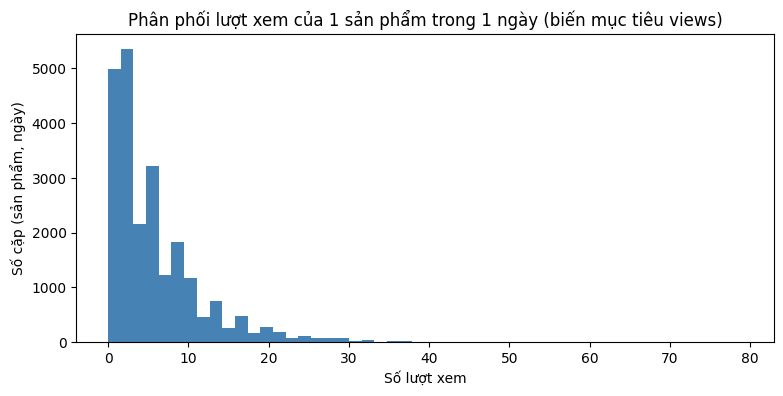

In [ ]:
eda = panel[panel['date'] <= '2008-07-15']

print('Tỷ lệ ô có views = 0:', round((eda['views'] == 0).mean()*100, 1), '%')
print(eda['views'].describe().round(2))

plt.hist(eda['views'], bins=50, color='steelblue')
plt.title('Phân phối lượt xem của 1 sản phẩm trong 1 ngày (biến mục tiêu views)')
plt.xlabel('Số lượt xem')
plt.ylabel('Số cặp (sản phẩm, ngày)')
plt.show()

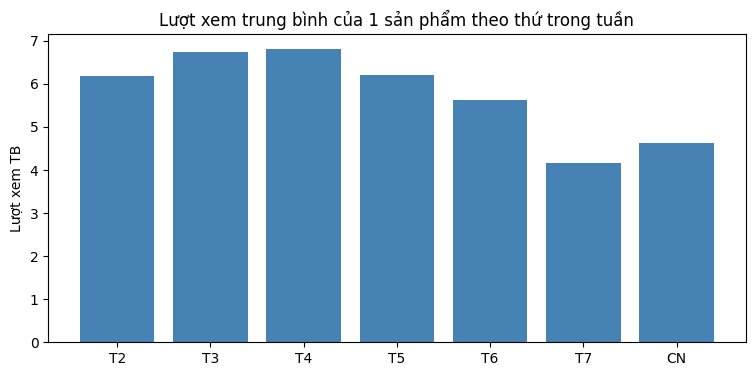

[6.17 6.75 6.81 6.2  5.63 4.17 4.62]


In [ ]:
day_names = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']
views_by_dow = eda.groupby(eda['date'].dt.dayofweek)['views'].mean()

plt.bar(day_names, views_by_dow.values, color='steelblue')
plt.title('Lượt xem trung bình của 1 sản phẩm theo thứ trong tuần')
plt.ylabel('Lượt xem TB')
plt.show()

print(views_by_dow.round(2).values)

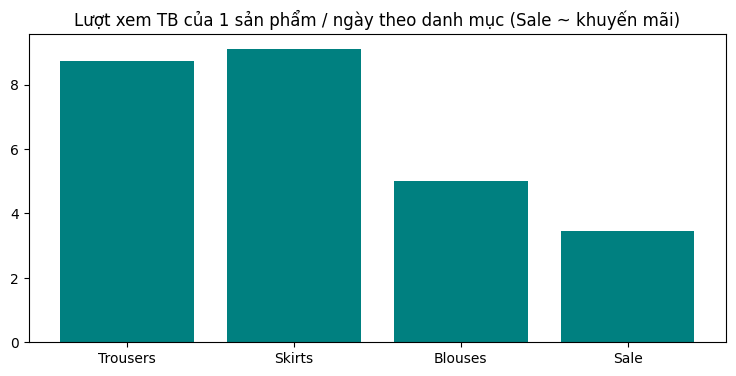

category
1    8.73
2    9.11
3    4.99
4    3.44
Name: views, dtype: float64


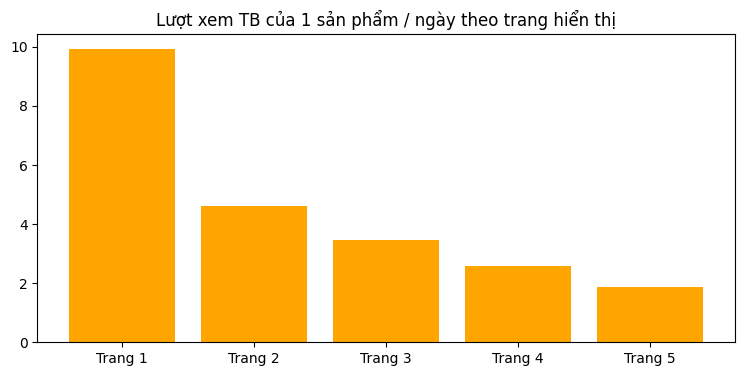

page
1    9.92
2    4.60
3    3.47
4    2.57
5    1.87
Name: views, dtype: float64
Số sản phẩm của mỗi danh mục nằm ở từng trang:


page,1,2,3,4,5
category,,,,,
Blouses,18,18,18,5,0
Sale,18,18,17,19,10
Skirts,17,16,0,0,0
Trousers,18,18,7,0,0


In [ ]:
category_names = {1: 'Trousers', 2: 'Skirts', 3: 'Blouses', 4: 'Sale'}

views_by_cat = eda.groupby('category')['views'].mean()
plt.bar(['Trousers', 'Skirts', 'Blouses', 'Sale'], views_by_cat.values, color='teal')
plt.title('Lượt xem TB của 1 sản phẩm / ngày theo danh mục (Sale ~ khuyến mãi)')
plt.show()
print(views_by_cat.round(2))

views_by_page = eda.groupby('page')['views'].mean()
plt.bar(['Trang 1', 'Trang 2', 'Trang 3', 'Trang 4', 'Trang 5'], views_by_page.values, color='orange')
plt.title('Lượt xem TB của 1 sản phẩm / ngày theo trang hiển thị')
plt.show()
print(views_by_page.round(2))

print('Số sản phẩm của mỗi danh mục nằm ở từng trang:')
pd.crosstab(catalog['category'].map(category_names), catalog['page'])

**Nhận xét từ khám phá:**
- `views` là **số đếm** (0, 1, 2, ...), lệch phải, khoảng 10% ô bằng 0 → khi đánh giá phải cẩn thận với MAPE (chia cho 0).
- Có **chu kỳ tuần** rõ: thứ 3, thứ 4 đông nhất, thứ 7 vắng nhất → tạo đặc trưng `day_of_week`.
- Sản phẩm ở **trang 1** được xem nhiều hơn hẳn các trang sau. Váy (Skirts) xem nhiều nhất nhưng toàn bộ váy nằm ở trang 1–2, còn hàng Sale rải đến trang 5 → khác biệt giữa danh mục có thể do **vị trí trưng bày** (biến gây nhiễu), không kết luận nhân quả.

**Bước 4.4: Tạo các đặc trưng lịch sử lượt xem.**
* **Nguyên tắc chống Data Leakage:** để dự báo ngày $d$, mọi đặc trưng chỉ được dùng thông tin từ ngày $d-1$ trở về trước → luôn `shift(1)` trước khi tính.
* Mọi phép tính làm **riêng cho từng sản phẩm** (`groupby('product')`) để dữ liệu của sản phẩm này không lẫn sang sản phẩm khác.

In [ ]:
def avg_last_7_days(x):
    return x.shift(1).rolling(7).mean()

def avg_last_14_days(x):
    return x.shift(1).rolling(14).mean()

grp = panel.groupby('product')['views']

panel['lag_1']       = grp.shift(1)
panel['lag_7']       = grp.shift(7)
panel['avg_7_days']  = grp.transform(avg_last_7_days)
panel['avg_14_days'] = grp.transform(avg_last_14_days)
panel['day_of_week'] = panel['date'].dt.dayofweek

panel[['product', 'date', 'views', 'lag_1', 'lag_7', 'avg_7_days', 'avg_14_days']].head(16)

,product,date,views,lag_1,lag_7,avg_7_days,avg_14_days
0,A1,2008-04-01,55.0,NaN,NaN,NaN,NaN
1,A1,2008-04-02,44.0,55.0,NaN,NaN,NaN
2,A1,2008-04-03,20.0,44.0,NaN,NaN,NaN
3,A1,2008-04-04,32.0,20.0,NaN,NaN,NaN
4,A1,2008-04-05,27.0,32.0,NaN,NaN,NaN
5,A1,2008-04-06,15.0,27.0,NaN,NaN,NaN
6,A1,2008-04-07,22.0,15.0,NaN,NaN,NaN
7,A1,2008-04-08,14.0,22.0,55.0,30.714286,NaN
8,A1,2008-04-09,19.0,14.0,44.0,24.857143,NaN
9,A1,2008-04-10,14.0,19.0,20.0,21.285714,NaN


**Bước 4.5: Kiểm tra bằng tay** cho sản phẩm A1, ngày 20/04: trung bình 7 ngày phải tính từ 13/04 đến 19/04 (không có ngày 20/04).

In [ ]:
a1 = panel[panel['product'] == 'A1'].set_index('date')['views']
print('Lượt xem A1 từ 13/04 đến 19/04:', a1['2008-04-13':'2008-04-19'].tolist())
print('Tự tính trung bình 7 ngày này :', round(a1['2008-04-13':'2008-04-19'].mean(), 3))

row = panel[(panel['product'] == 'A1') & (panel['date'] == '2008-04-20')]
print('Cột avg_7_days của ngày 20/04 :', round(row['avg_7_days'].values[0], 3))
print('Cột lag_1 của ngày 20/04      :', row['lag_1'].values[0], '| Lượt xem thật ngày 19/04:', a1['2008-04-19'])

Lượt xem A1 từ 13/04 đến 19/04: [12.0, 27.0, 19.0, 23.0, 16.0, 17.0, 11.0]
Tự tính trung bình 7 ngày này : 17.857
Cột avg_7_days của ngày 20/04 : 17.857
Cột lag_1 của ngày 20/04      : 11.0 | Lượt xem thật ngày 19/04: 11.0


**Bước 4.6:** 14 ngày đầu tiên (01/04 – 14/04) chưa đủ lịch sử để tính `avg_14_days` nên mang giá trị `NaN`. Nhóm loại 14 ngày khởi động này bằng `dropna(subset=...)`: chỉ xét các cột lịch sử, để không vô tình xoá dòng vì một cột khác.

In [ ]:
history_cols = ['lag_1', 'lag_7', 'avg_7_days', 'avg_14_days']
panel_clean = panel.dropna(subset=history_cols).reset_index(drop=True)
print('Kích thước bảng dữ liệu sạch:', panel_clean.shape)
print('Khoảng thời gian:', panel_clean['date'].min().date(), '->', panel_clean['date'].max().date())

Kích thước bảng dữ liệu sạch: (26040, 15)
Khoảng thời gian: 2008-04-15 -> 2008-08-12


---
## PHẦN 5: MÃ HÓA ONE-HOT & CHIA TRAIN / VALIDATION / TEST THEO THỜI GIAN
**Bước 5.1:** Các cột như `colour`, `page`, `day_of_week` là **mã số**, không phải đại lượng (thứ 7 không "lớn hơn" thứ 2). Nhóm dùng `pd.get_dummies` để tách mỗi cột mã thành các cột `0/1`.

In [ ]:
cat_cols = ['category', 'colour', 'location', 'photo', 'page', 'price2', 'day_of_week']
num_cols = ['price', 'lag_1', 'lag_7', 'avg_7_days', 'avg_14_days']

X_all = pd.get_dummies(panel_clean[cat_cols + num_cols], columns=cat_cols, drop_first=True, dtype=int)
y_all = panel_clean['views']

print('Kích thước ma trận đặc trưng X_all:', X_all.shape)
X_all.head(3)

Kích thước ma trận đặc trưng X_all: (26040, 38)


,price,lag_1,lag_7,avg_7_days,avg_14_days,category_2,category_3,category_4,colour_2,colour_3,...,page_3,page_4,page_5,price2_2,day_of_week_1,day_of_week_2,day_of_week_3,day_of_week_4,day_of_week_5,day_of_week_6
0,28,27.0,14.0,18.571429,24.642857,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
1,28,19.0,19.0,19.285714,22.071429,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
2,28,23.0,14.0,19.857143,20.571429,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0


**Bước 5.2:** Chia dữ liệu **theo thời gian** (không xáo trộn ngẫu nhiên), vì khi dùng thật mô hình luôn học từ quá khứ để đoán tương lai:
* **Train (15/04 – 15/07):** dùng để huấn luyện.
* **Validation (16/07 – 31/07):** dùng để chọn siêu tham số và chọn mô hình.
* **Test (01/08 – 12/08):** chỉ dùng **đúng 1 lần** ở bước đánh giá cuối cùng.

In [ ]:
train_mask = panel_clean['date'] <= '2008-07-15'
val_mask   = (panel_clean['date'] > '2008-07-15') & (panel_clean['date'] <= '2008-07-31')
test_mask  = panel_clean['date'] >= '2008-08-01'

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val,   y_val   = X_all[val_mask],   y_all[val_mask]
X_test,  y_test  = X_all[test_mask],  y_all[test_mask]

# Bảng mô tả 3 tập
rows = []
for name, mask in [('Train', train_mask), ('Validation', val_mask), ('Test', test_mask)]:
    part = panel_clean[mask]
    rows.append({'Tập': name, 'Từ ngày': part['date'].min().date(), 'Đến ngày': part['date'].max().date(), 'Số dòng': len(part)})
pd.DataFrame(rows)

,Tập,Từ ngày,Đến ngày,Số dòng
0,Train,2008-04-15,2008-07-15,19964
1,Validation,2008-07-16,2008-07-31,3472
2,Test,2008-08-01,2008-08-12,2604


---
## PHẦN 6: BASELINE VÀ CÁC MÔ HÌNH — CHỌN SIÊU THAM SỐ TRÊN VALIDATION
**Bước 6.1:** Viết một hàm `evaluate` tính 4 chỉ số. Thử hàm bằng một ví dụ nhỏ đã tính tay: thực tế `[10, 5, 0]`, dự đoán `[12, 4, 1]` → MAE = 1.333, RMSE = 1.414, MAPE = 20%, R² = 0.88.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0)
    nonzero = y_true > 0                          # MAPE chỉ tính khi lượt xem thật > 0
    return {'MAE':      round(mean_absolute_error(y_true, y_pred), 3),
            'RMSE':     round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),
            'MAPE (%)': round(np.mean(np.abs(y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero]) * 100, 1),
            'R2':       round(r2_score(y_true, y_pred), 3)}

evaluate([10, 5, 0], [12, 4, 1])

{'MAE': 1.333,
 'RMSE': np.float64(1.414),
 'MAPE (%)': np.float64(20.0),
 'R2': 0.88}

**Bước 6.2: Baseline** — cách đoán đơn giản không cần học. Mô hình Machine Learning chỉ có giá trị nếu thắng được các mốc này.

In [ ]:
val_results = {}
val_results['0a. Baseline: lượt xem hôm qua (lag_1)']    = evaluate(y_val, X_val['lag_1'])
val_results['0b. Baseline: cùng thứ tuần trước (lag_7)'] = evaluate(y_val, X_val['lag_7'])
val_results['0c. Baseline: TB 7 ngày trước']            = evaluate(y_val, X_val['avg_7_days'])
val_results['0d. Baseline: TB 14 ngày trước']           = evaluate(y_val, X_val['avg_14_days'])

pd.DataFrame(val_results).T

,MAE,RMSE,MAPE (%),R2
0a. Baseline: lượt xem hôm qua (lag_1),2.666,3.744,70.2,0.533
0b. Baseline: cùng thứ tuần trước (lag_7),2.648,3.752,71.0,0.531
0c. Baseline: TB 7 ngày trước,2.182,3.105,58.9,0.679
0d. Baseline: TB 14 ngày trước,2.125,3.046,56.5,0.691


**Nhận xét:** Hai baseline dựa vào **một ngày** (hôm qua: 2.666, cùng thứ tuần trước: 2.648) kém hẳn hai baseline dựa vào **trung bình** (TB 7 ngày: 2.182, TB 14 ngày: 2.125), vì lượt xem của một ngày dao động ngẫu nhiên nhiều; trung bình càng dài càng khử được dao động. **TB 14 ngày là baseline mạnh nhất → đây là mốc chính mà các mô hình phải vượt qua.**

**Bước 6.3: Linear Regression chỉ với 1 đặc trưng `lag_1`** — xem mô hình học được công thức gì từ "lượt xem hôm qua".

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge

lr_lag1 = LinearRegression().fit(X_train[['lag_1']], y_train)
print('Công thức học được: views =', round(lr_lag1.intercept_, 3), '+', round(lr_lag1.coef_[0], 3), 'x lag_1')

name_lr_lag1 = '1a. Linear Regression (chỉ lag_1)'
val_results[name_lr_lag1] = evaluate(y_val, lr_lag1.predict(X_val[['lag_1']]))
pd.DataFrame(val_results).T

Công thức học được: views = 1.434 + 0.73 x lag_1


,MAE,RMSE,MAPE (%),R2
0a. Baseline: lượt xem hôm qua (lag_1),2.666,3.744,70.2,0.533
0b. Baseline: cùng thứ tuần trước (lag_7),2.648,3.752,71.0,0.531
0c. Baseline: TB 7 ngày trước,2.182,3.105,58.9,0.679
0d. Baseline: TB 14 ngày trước,2.125,3.046,56.5,0.691
1a. Linear Regression (chỉ lag_1),2.563,3.532,69.3,0.584


**Nhận xét:** Hệ số 0.730 nhỏ hơn 1 → mô hình "kéo" dự báo về gần mức trung bình (hôm qua cao bất thường thì mai thường thấp hơn). Mô hình này thắng baseline "hôm qua" nhưng vẫn thua xa "TB 14 ngày" (2.125) → **chỉ một đặc trưng là không đủ**.

**Bước 6.4: Linear Regression với toàn bộ đặc trưng.** Trước đó chuẩn hóa dữ liệu bằng `StandardScaler` (đưa các cột về cùng thang đo). Bộ chuẩn hóa chỉ được **học trên Train**, rồi áp dụng cho Validation.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_train = StandardScaler()
X_train_scaled = scaler_train.fit_transform(X_train)
X_val_scaled   = scaler_train.transform(X_val)

lr_temp = LinearRegression().fit(X_train_scaled, y_train)

name_lr = '1b. Linear Regression (tất cả đặc trưng)'
val_results[name_lr] = evaluate(y_val, lr_temp.predict(X_val_scaled))
pd.DataFrame(val_results).T

,MAE,RMSE,MAPE (%),R2
0a. Baseline: lượt xem hôm qua (lag_1),2.666,3.744,70.2,0.533
0b. Baseline: cùng thứ tuần trước (lag_7),2.648,3.752,71.0,0.531
0c. Baseline: TB 7 ngày trước,2.182,3.105,58.9,0.679
0d. Baseline: TB 14 ngày trước,2.125,3.046,56.5,0.691
1a. Linear Regression (chỉ lag_1),2.563,3.532,69.3,0.584
1b. Linear Regression (tất cả đặc trưng),1.999,2.833,55.2,0.733


**Nhận xét:** Khi dùng đủ đặc trưng, MAE giảm từ 2.563 (chỉ `lag_1`) xuống 1.999, và lần đầu tiên **thắng baseline mạnh nhất TB 14 ngày** (2.125) → việc tạo đặc trưng (feature engineering) thật sự có ích.

**Bước 6.5: Ridge Regression** — Linear Regression có thêm "khoản phạt" cho hệ số quá lớn. Nhóm thử nhiều mức phạt `alpha` và chọn mức có MAE Validation thấp nhất.

In [ ]:
alphas = [0.1, 1, 10, 100, 1000, 10000]
ridge_val_maes = []
for a in alphas:
    ridge_temp = Ridge(alpha=a).fit(X_train_scaled, y_train)
    ridge_val_maes.append(evaluate(y_val, ridge_temp.predict(X_val_scaled))['MAE'])

print('MAE Validation theo alpha:', dict(zip(alphas, ridge_val_maes)))
best_alpha = alphas[np.argmin(ridge_val_maes)]
print('alpha tốt nhất:', best_alpha)

ridge_temp = Ridge(alpha=best_alpha).fit(X_train_scaled, y_train)
name_ridge = f'2. Ridge Regression (alpha={best_alpha})'
val_results[name_ridge] = evaluate(y_val, ridge_temp.predict(X_val_scaled))

MAE Validation theo alpha: {0.1: 1.999, 1: 1.999, 10: 1.999, 100: 2.001, 1000: 2.013, 10000: 2.108}
alpha tốt nhất: 0.1


**Nhận xét:** MAE gần như không đổi với `alpha` từ 0.1 đến 10 (1.999) → mô hình **không nhạy** với mức phạt trong vùng này; chỉ khi phạt mạnh (từ 1000 trở lên) MAE mới tăng. Vậy về độ chính xác, **Ridge không cải thiện so với Linear Regression** (Ridge với `alpha` nhỏ gần như chính là Linear Regression). Lý do: gần 20.000 dòng Train mà chỉ 38 cột, nên Linear Regression chưa bị học vẹt. Lưu ý: Ridge được huấn luyện để giảm sai số bình phương (MSE) nhưng nhóm chọn `alpha` theo MAE — hai tiêu chí này có thể chọn khác nhau.

**Ridge làm gì với các cột giống nhau?** `lag_1`, `avg_7_days`, `avg_14_days` đều đo "mức xem gần đây" nên rất giống nhau (đa cộng tuyến). Nhóm in tương quan và so sánh hệ số của Linear Regression với Ridge.

In [ ]:
history_feats = ['lag_1', 'lag_7', 'avg_7_days', 'avg_14_days']
print('Tương quan giữa các đặc trưng lịch sử (Train):')
print(X_train[history_feats].corr().round(3))

ridge_strong = Ridge(alpha=1000).fit(X_train_scaled, y_train)
coef_table = pd.DataFrame({
    'Linear Regression':           lr_temp.coef_,
    f'Ridge (alpha={best_alpha})': ridge_temp.coef_,
    'Ridge (alpha=1000)':          ridge_strong.coef_,
}, index=X_train.columns).loc[history_feats].round(3)
coef_table

Tương quan giữa các đặc trưng lịch sử (Train):
             lag_1  lag_7  avg_7_days  avg_14_days
lag_1        1.000  0.720       0.861        0.846
lag_7        0.720  1.000       0.861        0.851
avg_7_days   0.861  0.861       1.000        0.983
avg_14_days  0.846  0.851       0.983        1.000


,Linear Regression,Ridge (alpha=0.1),Ridge (alpha=1000)
lag_1,0.493,0.493,0.613
lag_7,0.207,0.207,0.410
avg_7_days,0.811,0.811,1.277
avg_14_days,2.696,2.696,1.799


**Nhận xét:** `avg_7_days` và `avg_14_days` tương quan 0.983 — gần như cùng một thông tin. Với `alpha = 0.1`, hệ số Ridge trùng hệt Linear Regression. Khi phạt mạnh (`alpha = 1000`), Ridge **chia đều trọng số** cho các cột giống nhau: hệ số của `avg_14_days` giảm từ 2.70 xuống 1.80, còn `avg_7_days`, `lag_7`, `lag_1` tăng lên. Mô hình khi đó dễ giải thích hơn (không "dồn" vào một cột) nhưng MAE Validation kém đi một chút (2.013 so với 1.999).

**Bước 6.6: KNN (K-Nearest Neighbors)** — dự báo bằng trung bình lượt xem của `k` tình huống trong quá khứ **giống nhất** với hôm nay. KNN đo "giống" bằng khoảng cách, nên (1) bắt buộc chuẩn hóa, (2) các cột không liên quan cũng bị tính vào khoảng cách. Vì vậy nhóm thử 3 bộ đặc trưng và 5 giá trị `k` trên Validation.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

dow_cols = ['day_of_week_1', 'day_of_week_2', 'day_of_week_3', 'day_of_week_4', 'day_of_week_5', 'day_of_week_6']
knn_feature_sets = {
    'Tất cả 38 cột':       list(X_all.columns),
    '4 cột lịch sử':       history_cols,
    '4 cột lịch sử + thứ': history_cols + dow_cols,
}
ks = [10, 30, 50, 100, 200]

knn_rows = []
for set_name in knn_feature_sets:
    cols = knn_feature_sets[set_name]
    knn_scaler = StandardScaler().fit(X_train[cols])
    for k in ks:
        knn_temp = KNeighborsRegressor(n_neighbors=k).fit(knn_scaler.transform(X_train[cols]), y_train)
        mae = evaluate(y_val, knn_temp.predict(knn_scaler.transform(X_val[cols])))['MAE']
        knn_rows.append({'Bộ đặc trưng': set_name, 'k': k, 'MAE Validation': mae})

knn_table = pd.DataFrame(knn_rows)
knn_table

,Bộ đặc trưng,k,MAE Validation
0,Tất cả 38 cột,10,2.382
1,Tất cả 38 cột,30,2.337
2,Tất cả 38 cột,50,2.329
3,Tất cả 38 cột,100,2.338
4,Tất cả 38 cột,200,2.412
5,4 cột lịch sử,10,2.153
6,4 cột lịch sử,30,2.100
7,4 cột lịch sử,50,2.088
8,4 cột lịch sử,100,2.083
9,4 cột lịch sử,200,2.087


**Nhận xét:** Cùng một thuật toán KNN nhưng kết quả rất khác nhau theo bộ đặc trưng:
- **38 cột**: tệ nhất (tốt nhất chỉ 2.329), còn **thua cả baseline TB 14 ngày** (2.125). Các cột 0/1 về màu, vị trí ảnh, trang… không liên quan nhiều đến lượt xem ngày mai nhưng vẫn được tính vào khoảng cách, làm KNN tìm sai "hàng xóm".
- **4 cột lịch sử**: tốt hơn hẳn (2.083).
- **4 cột lịch sử + thứ trong tuần**: tốt nhất (1.985 ở `k = 50`), vì thứ trong tuần thật sự ảnh hưởng đến lượt xem.

Về `k`: `k` nhỏ (10) thì dự báo dựa vào quá ít hàng xóm nên dao động nhiều; `k` quá lớn (200) thì trung bình quá nhiều tình huống khác nhau nên mất chi tiết. `k = 50` nằm ở giữa lưới đã thử.

In [ ]:
best_knn = knn_table.sort_values('MAE Validation').iloc[0]      # dòng có MAE nhỏ nhất
best_knn_set = best_knn['Bộ đặc trưng']
best_k = int(best_knn['k'])
knn_cols = knn_feature_sets[best_knn_set]
print('KNN tốt nhất trên Validation:', best_knn_set, '| k =', best_k)

knn_scaler = StandardScaler().fit(X_train[knn_cols])
knn_temp = KNeighborsRegressor(n_neighbors=best_k).fit(knn_scaler.transform(X_train[knn_cols]), y_train)
name_knn = f'3. KNN (k={best_k}, {best_knn_set})'
val_results[name_knn] = evaluate(y_val, knn_temp.predict(knn_scaler.transform(X_val[knn_cols])))

KNN tốt nhất trên Validation: 4 cột lịch sử + thứ | k = 50


**Bước 6.7: Decision Tree** — tìm độ sâu `max_depth` tốt nhất trên Validation để tránh học vẹt (overfitting). Cây không cần chuẩn hóa dữ liệu.

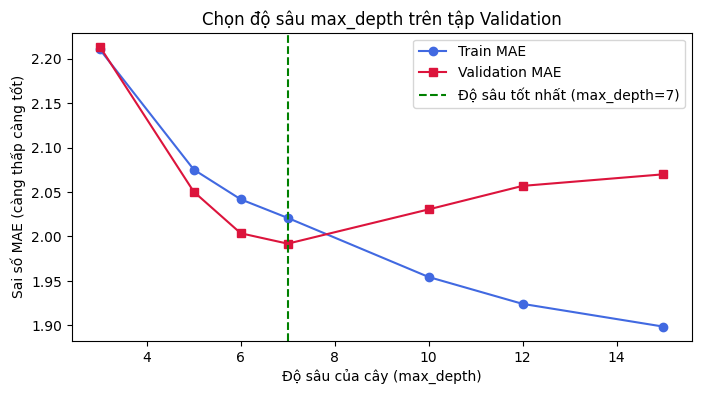

max_depth tốt nhất: 7


In [ ]:
from sklearn.tree import DecisionTreeRegressor

depths = [3, 5, 6, 7, 10, 12, 15]
train_maes, val_maes = [], []

for d in depths:
    dt_temp = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42)
    dt_temp.fit(X_train, y_train)
    train_maes.append(mean_absolute_error(y_train, dt_temp.predict(X_train)))
    val_maes.append(mean_absolute_error(y_val, dt_temp.predict(X_val)))

best_depth = depths[np.argmin(val_maes)]

plt.figure(figsize=(8, 4))
plt.plot(depths, train_maes, marker='o', label='Train MAE', color='royalblue')
plt.plot(depths, val_maes, marker='s', label='Validation MAE', color='crimson')
plt.axvline(x=best_depth, color='green', linestyle='--', label=f'Độ sâu tốt nhất (max_depth={best_depth})')
plt.title('Chọn độ sâu max_depth trên tập Validation')
plt.xlabel('Độ sâu của cây (max_depth)')
plt.ylabel('Sai số MAE (càng thấp càng tốt)')
plt.legend()
plt.show()

print('max_depth tốt nhất:', best_depth)
dt_temp = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=42).fit(X_train, y_train)
name_dt = f'4. Decision Tree (max_depth={best_depth})'
val_results[name_dt] = evaluate(y_val, dt_temp.predict(X_val))

**Nhận xét:** Khi cây sâu dần, MAE trên Train **giảm liên tục** (2.21 → 1.90), nhưng MAE trên Validation chỉ giảm đến `max_depth = 7` (1.992) rồi **tăng trở lại** (2.07 ở độ sâu 15) → cây quá sâu bắt đầu học vẹt Train. Đây chính là hình ảnh của **overfitting**.

**Bước 6.8: Random Forest** — trung bình của 100 cây quyết định. Nhóm thử vài giá trị `max_depth` trên Validation.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_depths = [6, 8, 10, 12]
rf_val_maes = []
for d in rf_depths:
    rf_temp = RandomForestRegressor(n_estimators=100, max_depth=d, min_samples_leaf=20, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train, y_train)
    rf_val_maes.append(evaluate(y_val, rf_temp.predict(X_val))['MAE'])

print('MAE Validation theo max_depth:', dict(zip(rf_depths, rf_val_maes)))
best_rf_depth = rf_depths[np.argmin(rf_val_maes)]
print('max_depth tốt nhất cho Random Forest:', best_rf_depth)

rf_temp = RandomForestRegressor(n_estimators=100, max_depth=best_rf_depth, min_samples_leaf=20,
                                random_state=42, n_jobs=-1).fit(X_train, y_train)
name_rf = f'5. Random Forest (100 cây, max_depth={best_rf_depth})'
val_results[name_rf] = evaluate(y_val, rf_temp.predict(X_val))

MAE Validation theo max_depth: {6: 1.98, 8: 1.963, 10: 1.965, 12: 1.968}
max_depth tốt nhất cho Random Forest: 8


**Nhận xét:** Random Forest tốt nhất ở `max_depth = 8` (MAE 1.963), giá trị này nằm ở giữa các giá trị đã thử (không nằm ở rìa).

**Bước 6.9:** Bảng tổng hợp trên Validation, sắp xếp theo MAE. Mô hình có MAE Validation thấp nhất được chọn. **Đến đây nhóm chưa dùng tập Test lần nào.**

In [ ]:
val_table = pd.DataFrame(val_results).T.sort_values('MAE')
display(val_table)

best_model_name = val_table.index[0]
print('Mô hình được chọn (MAE Validation thấp nhất):', best_model_name)

,MAE,RMSE,MAPE (%),R2
"5. Random Forest (100 cây, max_depth=8)",1.963,2.787,51.6,0.741
"3. KNN (k=50, 4 cột lịch sử + thứ)",1.984,2.799,52.8,0.739
4. Decision Tree (max_depth=7),1.992,2.845,52.0,0.730
1b. Linear Regression (tất cả đặc trưng),1.999,2.833,55.2,0.733
2. Ridge Regression (alpha=0.1),1.999,2.833,55.2,0.733
0d. Baseline: TB 14 ngày trước,2.125,3.046,56.5,0.691
0c. Baseline: TB 7 ngày trước,2.182,3.105,58.9,0.679
1a. Linear Regression (chỉ lag_1),2.563,3.532,69.3,0.584
0b. Baseline: cùng thứ tuần trước (lag_7),2.648,3.752,71.0,0.531
0a. Baseline: lượt xem hôm qua (lag_1),2.666,3.744,70.2,0.533


Mô hình được chọn (MAE Validation thấp nhất): 5. Random Forest (100 cây, max_depth=8)


**Nhận xét:** Cả 5 mô hình học máy (trừ Linear Regression chỉ dùng `lag_1`) đều thắng cả 4 baseline. Random Forest đứng đầu, KNN đứng thứ hai, nhưng các mô hình học máy chỉ chênh nhau 1.963 – 1.999, và ngay cả khoảng cách từ baseline mạnh nhất lên mô hình tốt nhất cũng chỉ là 2.125 → 1.963. Trong khi đó, chỉ riêng việc đổi từ "hôm qua" sang "TB 14 ngày" đã giảm 2.666 → 2.125 → **phần lớn độ chính xác đến từ việc dùng đúng thông tin lịch sử (đặc trưng)**, không phải từ thuật toán phức tạp.

---
## PHẦN 7: HUẤN LUYỆN LẠI & ĐÁNH GIÁ MỘT LẦN TRÊN TEST
Các siêu tham số đã chọn xong. Nhóm gộp Train + Validation (toàn bộ dữ liệu đến 31/07) để huấn luyện lại, vì 16 ngày cuối tháng 7 là dữ liệu gần tháng 8 nhất. Sau đó dự báo tập Test (01/08 – 12/08) **một lần duy nhất**.

In [ ]:
dev_mask = panel_clean['date'] <= '2008-07-31'
X_dev, y_dev = X_all[dev_mask], y_all[dev_mask]

scaler = StandardScaler()
X_dev_scaled  = scaler.fit_transform(X_dev)
X_test_scaled = scaler.transform(X_test)

# 0. Baseline
pred_lag1  = X_test['lag_1']
pred_lag7  = X_test['lag_7']
pred_avg7  = X_test['avg_7_days']
pred_avg14 = X_test['avg_14_days']

# 1a. Linear Regression chỉ với lag_1
pred_lr_lag1 = LinearRegression().fit(X_dev[['lag_1']], y_dev).predict(X_test[['lag_1']])

# 1b. Linear Regression với toàn bộ đặc trưng
lr_model = LinearRegression().fit(X_dev_scaled, y_dev)
pred_lr  = lr_model.predict(X_test_scaled)

# 2. Ridge Regression với alpha tốt nhất
ridge_model = Ridge(alpha=best_alpha).fit(X_dev_scaled, y_dev)
pred_ridge  = ridge_model.predict(X_test_scaled)

# 3. KNN với bộ đặc trưng và k tốt nhất (chuẩn hóa lại trên Train + Validation)
knn_scaler_dev = StandardScaler().fit(X_dev[knn_cols])
knn_model = KNeighborsRegressor(n_neighbors=best_k).fit(knn_scaler_dev.transform(X_dev[knn_cols]), y_dev)
pred_knn  = knn_model.predict(knn_scaler_dev.transform(X_test[knn_cols]))

# 4. Decision Tree với max_depth tốt nhất
dt_model = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=42).fit(X_dev, y_dev)
pred_dt  = dt_model.predict(X_test)

# 5. Random Forest với max_depth tốt nhất
rf_model = RandomForestRegressor(n_estimators=100, max_depth=best_rf_depth, min_samples_leaf=20,
                                 random_state=42, n_jobs=-1).fit(X_dev, y_dev)
pred_rf  = rf_model.predict(X_test)

print('Huấn luyện hoàn tất!')

Huấn luyện hoàn tất!


In [ ]:
test_preds = {
    '0a. Baseline: lượt xem hôm qua (lag_1)':    pred_lag1,
    '0b. Baseline: cùng thứ tuần trước (lag_7)': pred_lag7,
    '0c. Baseline: TB 7 ngày trước':            pred_avg7,
    '0d. Baseline: TB 14 ngày trước':           pred_avg14,
    name_lr_lag1: pred_lr_lag1,
    name_lr:      pred_lr,
    name_ridge:   pred_ridge,
    name_knn:     pred_knn,
    name_dt:      pred_dt,
    name_rf:      pred_rf,
}

test_results = {}
for name in test_preds:
    test_results[name] = evaluate(y_test, test_preds[name])

# Bảng so sánh: mỗi mô hình 1 dòng, có cả MAE Validation và kết quả Test
rows = []
for name in test_preds:
    rows.append({'Mô hình': name,
                 'Val MAE':       val_results[name]['MAE'],
                 'Test MAE':      test_results[name]['MAE'],
                 'Test RMSE':     test_results[name]['RMSE'],
                 'Test MAPE (%)': test_results[name]['MAPE (%)'],
                 'Test R2':       test_results[name]['R2']})
comparison_table = pd.DataFrame(rows).sort_values('Val MAE')
display(comparison_table)

# Tìm baseline MẠNH NHẤT theo Validation (không chọn theo Test)
baseline_names = ['0a. Baseline: lượt xem hôm qua (lag_1)', '0b. Baseline: cùng thứ tuần trước (lag_7)',
                  '0c. Baseline: TB 7 ngày trước', '0d. Baseline: TB 14 ngày trước']
best_baseline = baseline_names[0]
for name in baseline_names:
    if val_results[name]['MAE'] < val_results[best_baseline]['MAE']:
        best_baseline = name

best_mae = test_results[best_model_name]['MAE']
base_mae = test_results[best_baseline]['MAE']
print('Mô hình được chọn:', best_model_name)
print('Baseline mạnh nhất:', best_baseline)
print('Test MAE =', best_mae, 'so với', base_mae, '-> giảm', round((1 - best_mae / base_mae) * 100, 1), '% sai số')

,Mô hình,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2
9,"5. Random Forest (100 cây, max_depth=8)",1.963,2.023,2.938,50.5,0.711
7,"3. KNN (k=50, 4 cột lịch sử + thứ)",1.984,2.043,2.987,50.8,0.702
8,4. Decision Tree (max_depth=7),1.992,2.053,2.990,51.0,0.701
5,1b. Linear Regression (tất cả đặc trưng),1.999,2.078,2.991,53.9,0.701
6,2. Ridge Regression (alpha=0.1),1.999,2.078,2.991,53.9,0.701
3,0d. Baseline: TB 14 ngày trước,2.125,2.126,3.065,54.1,0.686
2,0c. Baseline: TB 7 ngày trước,2.182,2.168,3.114,54.8,0.676
4,1a. Linear Regression (chỉ lag_1),2.563,2.642,3.724,69.4,0.536
1,0b. Baseline: cùng thứ tuần trước (lag_7),2.648,2.627,3.779,67.7,0.522
0,0a. Baseline: lượt xem hôm qua (lag_1),2.666,2.740,3.986,70.9,0.469


Mô hình được chọn: 5. Random Forest (100 cây, max_depth=8)
Baseline mạnh nhất: 0d. Baseline: TB 14 ngày trước
Test MAE = 2.023 so với 2.126 -> giảm 4.8 % sai số


**Nhận xét:** Trên Test, các mô hình học máy giữ đúng thứ hạng như trên Validation (chỉ hai baseline yếu `lag_7` và Linear Regression chỉ `lag_1` đổi chỗ nhau). Random Forest có Test MAE 2.023, thấp hơn **baseline mạnh nhất TB 14 ngày (2.126) khoảng 4.8%** (so với TB 7 ngày là 6.7%, nhưng nhóm báo cáo con số so với baseline mạnh nhất cho trung thực). MAPE khoảng 50% nghe có vẻ cao vì có rất nhiều ô chỉ 1–3 lượt xem (thực tế 1, đoán 2 đã là sai 100%), nên nhóm dùng **MAE làm chỉ số chính**.

---
## PHẦN 8: PHÂN TÍCH KẾT QUẢ
**Bước 8.1: Thực tế và dự đoán** của mô hình được chọn trên tập Test.

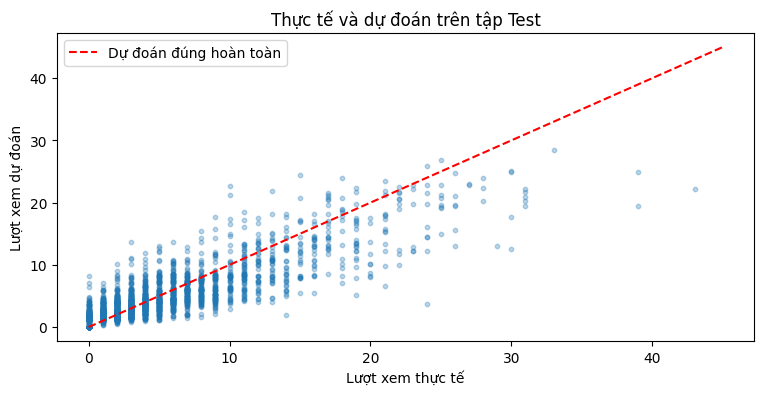

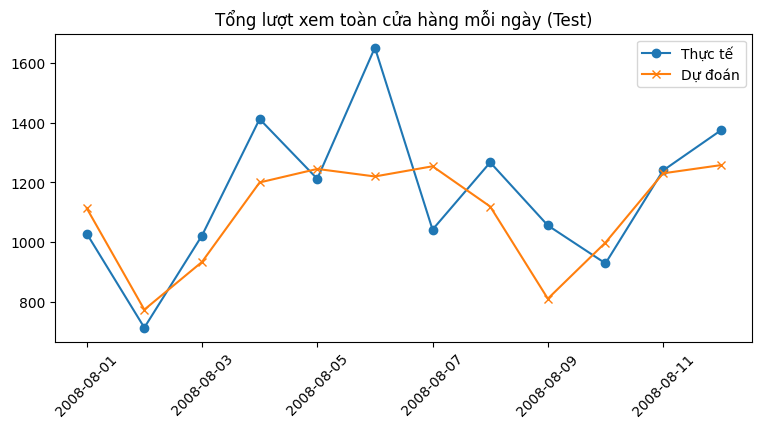

In [ ]:
best_pred = np.maximum(np.array(test_preds[best_model_name]), 0)

test_view = panel_clean[test_mask].copy()
test_view['pred'] = best_pred

# Biểu đồ 1: mỗi điểm là 1 sản phẩm trong 1 ngày
plt.scatter(test_view['views'], test_view['pred'], alpha=0.3, s=10)
plt.plot([0, 45], [0, 45], 'r--', label='Dự đoán đúng hoàn toàn')
plt.xlabel('Lượt xem thực tế')
plt.ylabel('Lượt xem dự đoán')
plt.title('Thực tế và dự đoán trên tập Test')
plt.legend()
plt.show()

# Biểu đồ 2: tổng lượt xem toàn cửa hàng mỗi ngày
daily_compare = test_view.groupby('date')[['views', 'pred']].sum()
plt.plot(daily_compare.index, daily_compare['views'], marker='o', label='Thực tế')
plt.plot(daily_compare.index, daily_compare['pred'], marker='x', label='Dự đoán')
plt.title('Tổng lượt xem toàn cửa hàng mỗi ngày (Test)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

**Nhận xét:** Với những ô có lượt xem thật rất cao, các điểm thường nằm **dưới** đường đỏ → mô hình đoán thấp những ngày đột biến. Ở biểu đồ tổng theo ngày, dự đoán bám theo xu hướng chung nhưng không bắt được các ngày tăng vọt như 04/08 và 06/08 (thực tế 1.651 so với dự đoán 1.220), vì không có đặc trưng nào báo trước những cú sốc này.

**Bước 8.2: Mô hình thắng baseline mạnh nhất bao nhiêu ngày?** Một con số MAE trung bình có thể bị vài ngày kéo lệch, nên nhóm so sánh từng ngày trong 12 ngày Test với baseline TB 14 ngày.

In [ ]:
test_view['err_model']    = (test_view['views'] - test_view['pred']).abs()
test_view['err_baseline'] = (test_view['views'] - test_view['avg_14_days']).abs()

daily_mae = test_view.groupby('date')[['err_model', 'err_baseline']].mean()
daily_mae.columns = ['MAE mô hình', 'MAE baseline TB 14 ngày']
daily_mae['Mô hình thắng?'] = daily_mae['MAE mô hình'] < daily_mae['MAE baseline TB 14 ngày']
display(daily_mae.round(3))

wins = daily_mae['Mô hình thắng?'].sum()
print('Mô hình thắng', wins, '/', len(daily_mae), 'ngày')

,MAE mô hình,MAE baseline TB 14 ngày,Mô hình thắng?
date,,,
2008-08-01,1.887,1.889,True
2008-08-02,1.650,2.424,True
2008-08-03,1.786,1.935,True
2008-08-04,2.190,2.183,False
2008-08-05,2.006,2.001,False
2008-08-06,2.513,2.781,True
2008-08-07,1.919,1.787,False
2008-08-08,2.151,2.121,False
2008-08-09,2.182,2.122,False


Mô hình thắng 7 / 12 ngày


**Thắng 7/12 ngày có phải do may mắn không?** Nếu mô hình và baseline thật sự **ngang tài**, mỗi ngày ai thắng cũng giống **tung đồng xu**. Nhóm mô phỏng: tung 12 đồng xu, lặp lại 10.000 lần, đếm xem bao nhiêu lần được **ít nhất** số "mặt thắng" như mô hình. Nếu tỷ lệ này lớn, thì kết quả của mô hình hoàn toàn có thể chỉ do may mắn.

In [ ]:
np.random.seed(42)
n_days = len(daily_mae)

lucky = 0
for i in range(10000):
    heads = np.random.randint(0, 2, n_days).sum()
    if heads >= wins:
        lucky = lucky + 1

lucky_rate = lucky / 10000
print('Nếu mô hình và baseline NGANG TÀI, tỷ lệ thắng ≥', wins, '/', n_days, 'ngày chỉ nhờ may mắn:', round(lucky_rate * 100, 1), '%')

Nếu mô hình và baseline NGANG TÀI, tỷ lệ thắng ≥ 7 / 12 ngày chỉ nhờ may mắn: 39.1 %


**Nhận xét:** Khoảng **39%** số lần, chỉ tung đồng xu may rủi cũng được ít nhất 7/12 "ngày thắng". Tức là: nếu mô hình chẳng hề tốt hơn baseline, thì kết quả "thắng 7/12 ngày" vẫn xảy ra khá thường xuyên. Vì vậy **12 ngày Test chưa đủ bằng chứng** để khẳng định mô hình tốt hơn baseline TB 14 ngày. (Tỷ lệ này trong thống kê gọi là *p-value*; thường phải nhỏ hơn 5% mới được coi là "khó do may mắn".) Kết luận trung thực: mô hình có MAE thấp hơn baseline trên cả Validation lẫn Test, nên **có tiềm năng cải thiện dự báo**, nhưng **chưa đủ bằng chứng để khẳng định chắc chắn**; cần đánh giá trên nhiều giai đoạn thời gian hơn.

**Bước 8.3: Mô hình sai nhiều ở nhóm nào?** Tính sai số theo danh mục. `Bias` = trung bình (dự đoán − thực tế): dương là đoán dư, âm là đoán thiếu.

In [ ]:
test_view['error']     = test_view['pred'] - test_view['views']
test_view['abs_error'] = test_view['error'].abs()

error_by_cat = pd.DataFrame({
    'Lượt xem TB thực tế': test_view.groupby('category')['views'].mean(),
    'MAE':                 test_view.groupby('category')['abs_error'].mean(),
    'Bias':                test_view.groupby('category')['error'].mean(),
}).rename(index=category_names).round(3)

# Kiểm tra lại khi bỏ 4 sản phẩm đã ngừng xuất hiện (danh sách `inactive` ở Phần 4)
active = ~test_view['product'].isin(inactive)
print('Tất cả sản phẩm            -> MAE mô hình:', round(test_view['abs_error'].mean(), 3),
      '| MAE baseline TB 14 ngày:', round(test_view['err_baseline'].mean(), 3))
print('Bỏ 4 sản phẩm đã ngừng bán -> MAE mô hình:', round(test_view[active]['abs_error'].mean(), 3),
      '| MAE baseline TB 14 ngày:', round(test_view[active]['err_baseline'].mean(), 3))

error_by_cat

Tất cả sản phẩm            -> MAE mô hình: 2.023 | MAE baseline TB 14 ngày: 2.126
Bỏ 4 sản phẩm đã ngừng bán -> MAE mô hình: 2.061 | MAE baseline TB 14 ngày: 2.166


,Lượt xem TB thực tế,MAE,Bias
category,,,
Trousers,7.882,2.546,-0.460
Skirts,6.992,2.526,-0.261
Blouses,4.527,1.990,-0.352
Sale,3.971,1.570,-0.203


**Nhận xét:** MAE cao nhất ở danh mục đông khách (Trousers, Skirts) vì lượt xem lớn thì sai lệch tuyệt đối cũng lớn hơn. `Bias` âm ở cả 4 danh mục → trong tháng 8 mô hình **đoán thiếu nhẹ** (trung bình dự đoán 5.05 so với thực tế 5.36 lượt/sản phẩm/ngày), không có danh mục nào bị lệch hẳn so với các danh mục khác. Khi bỏ 4 sản phẩm đã ngừng bán, MAE của cả mô hình (2.061) và baseline (2.166) đều tăng nhẹ, nhưng mức cải thiện vẫn giữ nguyên khoảng 4.8% → kết luận không phụ thuộc vào các dòng "dễ đoán" này.

**Bước 8.4: Mức độ quan trọng của đặc trưng** trong mô hình Random Forest.

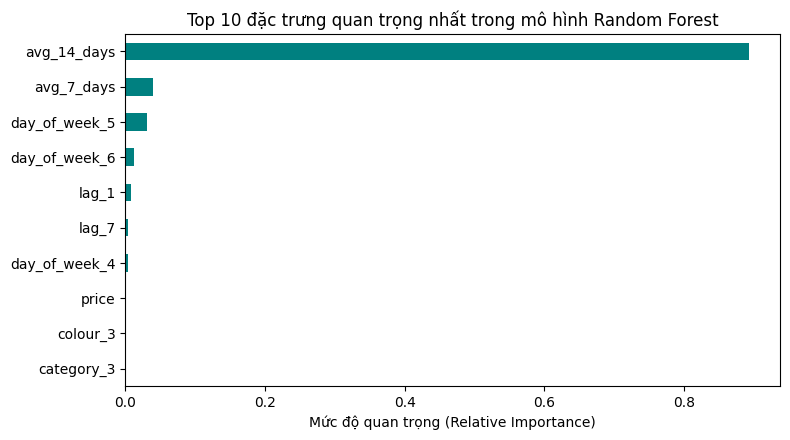

avg_14_days      0.893
avg_7_days       0.040
day_of_week_5    0.031
day_of_week_6    0.013
lag_1            0.008
lag_7            0.004
day_of_week_4    0.003
price            0.001
colour_3         0.001
category_3       0.001
dtype: float64


In [ ]:
importances = pd.Series(rf_model.feature_importances_, index=X_all.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4.5))
importances.plot(kind='barh', color='teal')
plt.title('Top 10 đặc trưng quan trọng nhất trong mô hình Random Forest')
plt.xlabel('Mức độ quan trọng (Relative Importance)')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(3))

**Nhận xét:** `avg_14_days` chiếm gần 90% tầm quan trọng → "mức độ được quan tâm trong 2 tuần gần đây" là manh mối mạnh nhất. `day_of_week_5` (thứ 7) đứng thứ 3, khớp với khám phá thứ 7 vắng nhất. Lưu ý: (1) các cột giống nhau (`avg_7_days`, `avg_14_days`) chia nhau tầm quan trọng nên cột đứng sau bị đánh giá thấp; (2) one-hot tách `day_of_week` thành nhiều cột nhỏ; (3) tầm quan trọng chỉ cho biết mô hình **dựa vào** cột nào, không chứng minh cột đó **gây ra** lượt xem.

**Bước 8.5: Thử nghiệm cố tình làm SAI** — nếu quên `shift(1)`, trung bình 7 ngày sẽ chứa luôn lượt xem của chính ngày cần dự báo. Nhóm đo xem điểm số "đẹp giả" đến mức nào (cùng mô hình Random Forest).

In [ ]:
def avg_7_days_WRONG(x):
    return x.rolling(7, min_periods=1).mean()      # SAI: không shift(1) nên chứa luôn ngày đang dự báo

X_wrong = X_all.copy()
X_wrong['avg_7_days'] = panel_clean.groupby('product')['views'].transform(avg_7_days_WRONG)

rf_wrong = RandomForestRegressor(n_estimators=100, max_depth=best_rf_depth, min_samples_leaf=20,
                                 random_state=42, n_jobs=-1).fit(X_wrong[dev_mask], y_dev)

print('Random Forest ĐÚNG (có shift):', evaluate(y_test, pred_rf))
print('Random Forest SAI (quên shift):', evaluate(y_test, rf_wrong.predict(X_wrong[test_mask])))

Random Forest ĐÚNG (có shift): {'MAE': 2.023, 'RMSE': np.float64(2.938), 'MAPE (%)': np.float64(50.5), 'R2': 0.711}
Random Forest SAI (quên shift): {'MAE': 1.739, 'RMSE': np.float64(2.53), 'MAPE (%)': np.float64(43.5), 'R2': 0.786}


**Nhận xét:** Quên `shift(1)` làm MAE giảm từ 2.023 xuống 1.739 và R² tăng từ 0.711 lên 0.786 — nhưng đây là **điểm giả**: khi dùng thật, tối hôm trước không ai biết lượt xem của ngày mai. Đây là lý do nhóm luôn `shift(1)` và kiểm tra bằng tay ở Bước 4.5.

---
## PHẦN 9: GÓC NHÌN KHÁC — ĐẶT BÀI TOÁN DẠNG PHÂN LOẠI
Logistic Regression và Naive Bayes chỉ dự đoán **nhãn** (có/không), nên không dùng được cho bài toán chính. Nhóm thử một câu hỏi dạng có/không để vừa áp dụng đúng các thuật toán này, vừa kiểm tra: **đặt bài toán kiểu khác có tốt hơn không?**

> **Câu hỏi:** Ngày mai sản phẩm có thuộc nhóm **được quan tâm cao** không?
> **Nhãn = 1** nếu lượt xem ngày mai ≥ ngưỡng. **Ngưỡng = phân vị 75% lượt xem trên Train** (tức chỉ ~1/4 số trường hợp là "quan tâm cao"). Ngưỡng tính **chỉ trên Train** để không dùng thông tin của Validation/Test.

**Bước 9.1:** Tạo nhãn.

In [ ]:
hot_threshold = y_train.quantile(0.75)
print('Ngưỡng "quan tâm cao":', hot_threshold, 'lượt xem/ngày')

y_train_hot = (y_train >= hot_threshold).astype(int)
y_val_hot   = (y_val   >= hot_threshold).astype(int)
y_dev_hot   = (y_dev   >= hot_threshold).astype(int)
y_test_hot  = (y_test  >= hot_threshold).astype(int)

print('Tỷ lệ nhãn 1 — Train:', round(y_train_hot.mean()*100, 1), '% | Validation:', round(y_val_hot.mean()*100, 1),
      '% | Test:', round(y_test_hot.mean()*100, 1), '%')

Ngưỡng "quan tâm cao": 7.0 lượt xem/ngày
Tỷ lệ nhãn 1 — Train: 29.4 % | Validation: 28.7 % | Test: 28.8 %


**Nhận xét:** Ngưỡng là **7 lượt xem/ngày**. Tỷ lệ nhãn 1 gần như bằng nhau ở cả 3 tập (~29%), nên ngưỡng tính trên Train dùng được cho Validation và Test.

**Bước 9.2: Chọn chỉ số đánh giá.** Chỉ ~29% là nhãn 1, nên **Accuracy dễ đánh lừa**: luôn đoán "không" cũng được ~71% Accuracy mà vô dụng. Nhóm dùng thêm:
* **Precision**: trong các sản phẩm mô hình bảo "quan tâm cao", bao nhiêu % đúng.
* **Recall**: trong các sản phẩm thật sự "quan tâm cao", mô hình bắt được bao nhiêu %.
* **F1**: trung bình điều hòa của Precision và Recall → **chỉ số chính để chọn mô hình**.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_cls(y_true, y_pred):
    return {'Accuracy':  round(accuracy_score(y_true, y_pred), 3),
            'Precision': round(precision_score(y_true, y_pred), 3),
            'Recall':    round(recall_score(y_true, y_pred), 3),
            'F1':        round(f1_score(y_true, y_pred), 3)}

print('Luôn đoán "không" trên Validation -> Accuracy:', round((y_val_hot == 0).mean() * 100, 1), '%, nhưng F1 = 0')

Luôn đoán "không" trên Validation -> Accuracy: 71.3 %, nhưng F1 = 0


**Bước 9.3: So sánh trên Validation.** Ngoài 5 thuật toán phân loại, nhóm thêm 2 cách làm đơn giản để so sánh:
* **Luật (baseline):** "quan tâm cao" nếu TB 14 ngày ≥ ngưỡng.
* **Dùng lại mô hình hồi quy:** "quan tâm cao" nếu lượt xem do Random Forest hồi quy dự báo ≥ ngưỡng.

Các siêu tham số dùng lại từ Phần 6 (cùng độ sâu cây, cùng `k`), không tune lại. Lệnh `.predict()` của các mô hình phân loại tự dùng ngưỡng xác suất 0.5 để ra nhãn 0/1.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cls_val = {}

# 0. Luật đơn giản: TB 14 ngày ≥ ngưỡng
rule_val = (X_val['avg_14_days'] >= hot_threshold).astype(int)
cls_val['0. Luật: TB 14 ngày ≥ ngưỡng'] = evaluate_cls(y_val_hot, rule_val)

# R. Dùng lại Random Forest hồi quy ở Phần 6 (đã học trên Train): lượt xem dự báo ≥ ngưỡng
reg_val = (rf_temp.predict(X_val) >= hot_threshold).astype(int)
cls_val['R. Random Forest hồi quy + ngưỡng'] = evaluate_cls(y_val_hot, reg_val)

# 1. Logistic Regression (dùng dữ liệu đã chuẩn hóa, giống Linear Regression)
logit_temp = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train_hot)
cls_val['1. Logistic Regression'] = evaluate_cls(y_val_hot, logit_temp.predict(X_val_scaled))

# 2. Gaussian Naive Bayes: thử với 38 cột và với 4 cột lịch sử
nb_temp = GaussianNB().fit(X_train, y_train_hot)
cls_val['2a. Naive Bayes (38 cột)'] = evaluate_cls(y_val_hot, nb_temp.predict(X_val))

nb_hist_temp = GaussianNB().fit(X_train[history_cols], y_train_hot)
cls_val['2b. Naive Bayes (4 cột lịch sử)'] = evaluate_cls(y_val_hot, nb_hist_temp.predict(X_val[history_cols]))

# 3. KNN (cùng bộ đặc trưng và k như Phần 6)
knn_c_temp = KNeighborsClassifier(n_neighbors=best_k).fit(knn_scaler.transform(X_train[knn_cols]), y_train_hot)
cls_val[f'3. KNN (k={best_k})'] = evaluate_cls(y_val_hot, knn_c_temp.predict(knn_scaler.transform(X_val[knn_cols])))

# 4. Decision Tree và 5. Random Forest (cùng siêu tham số như Phần 6)
dt_c_temp = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, random_state=42).fit(X_train, y_train_hot)
cls_val[f'4. Decision Tree (max_depth={best_depth})'] = evaluate_cls(y_val_hot, dt_c_temp.predict(X_val))

rf_c_temp = RandomForestClassifier(n_estimators=100, max_depth=best_rf_depth, min_samples_leaf=20,
                                   random_state=42, n_jobs=-1).fit(X_train, y_train_hot)
cls_val[f'5. Random Forest (max_depth={best_rf_depth})'] = evaluate_cls(y_val_hot, rf_c_temp.predict(X_val))

cls_val_table = pd.DataFrame(cls_val).T.sort_values('F1', ascending=False)
display(cls_val_table)

best_cls_name = cls_val_table.index[0]
print('Cách làm có F1 Validation cao nhất:', best_cls_name)

,Accuracy,Precision,Recall,F1
4. Decision Tree (max_depth=7),0.863,0.805,0.687,0.741
R. Random Forest hồi quy + ngưỡng,0.861,0.814,0.668,0.734
3. KNN (k=50),0.854,0.809,0.641,0.715
5. Random Forest (max_depth=8),0.854,0.812,0.639,0.715
1. Logistic Regression,0.855,0.828,0.623,0.711
0. Luật: TB 14 ngày ≥ ngưỡng,0.839,0.762,0.639,0.695
2b. Naive Bayes (4 cột lịch sử),0.842,0.776,0.629,0.695
2a. Naive Bayes (38 cột),0.821,0.779,0.526,0.628


Cách làm có F1 Validation cao nhất: 4. Decision Tree (max_depth=7)


**Nhận xét (Validation):**
- Mọi cách làm có học máy chỉ hơn **luật đơn giản** (F1 0.695) khoảng 0.02 – 0.05 F1. Decision Tree cao nhất (F1 0.741).
- **Dùng lại Random Forest hồi quy + ngưỡng** (F1 0.734) gần bằng mô hình phân loại tốt nhất → mô hình hồi quy đã chứa đủ thông tin để trả lời câu hỏi có/không.
- **Logistic Regression** (F1 0.711) có Precision cao nhất (0.828) nhưng Recall thấp (0.623): nó "thận trọng", ít khi bảo "quan tâm cao".
- **Naive Bayes với 38 cột kém nhất** (F1 0.628). Naive Bayes giả định các đặc trưng **độc lập** với nhau, trong khi 6 cột 0/1 của thứ trong tuần là các mảnh của cùng một biến, còn các cột trung bình tương quan 0.983 → mô hình "đếm trùng" bằng chứng. Chỉ dùng 4 cột lịch sử thì tốt hơn (F1 0.695), nhưng 4 cột này vẫn tương quan mạnh nên không vượt được luật đơn giản.

**Bước 9.4: Huấn luyện lại trên Train + Validation và đánh giá một lần trên Test** (giống Phần 7).

In [ ]:
cls_test = {}
cls_test['0. Luật: TB 14 ngày ≥ ngưỡng'] = evaluate_cls(y_test_hot, (X_test['avg_14_days'] >= hot_threshold).astype(int))
cls_test['R. Random Forest hồi quy + ngưỡng'] = evaluate_cls(y_test_hot, (pred_rf >= hot_threshold).astype(int))

logit_model = LogisticRegression(max_iter=1000).fit(X_dev_scaled, y_dev_hot)
cls_test['1. Logistic Regression'] = evaluate_cls(y_test_hot, logit_model.predict(X_test_scaled))

nb_model = GaussianNB().fit(X_dev, y_dev_hot)
cls_test['2a. Naive Bayes (38 cột)'] = evaluate_cls(y_test_hot, nb_model.predict(X_test))

nb_hist_model = GaussianNB().fit(X_dev[history_cols], y_dev_hot)
cls_test['2b. Naive Bayes (4 cột lịch sử)'] = evaluate_cls(y_test_hot, nb_hist_model.predict(X_test[history_cols]))

knn_c_model = KNeighborsClassifier(n_neighbors=best_k).fit(knn_scaler_dev.transform(X_dev[knn_cols]), y_dev_hot)
cls_test[f'3. KNN (k={best_k})'] = evaluate_cls(y_test_hot, knn_c_model.predict(knn_scaler_dev.transform(X_test[knn_cols])))

dt_c_model = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, random_state=42).fit(X_dev, y_dev_hot)
cls_test[f'4. Decision Tree (max_depth={best_depth})'] = evaluate_cls(y_test_hot, dt_c_model.predict(X_test))

rf_c_model = RandomForestClassifier(n_estimators=100, max_depth=best_rf_depth, min_samples_leaf=20,
                                    random_state=42, n_jobs=-1).fit(X_dev, y_dev_hot)
cls_test[f'5. Random Forest (max_depth={best_rf_depth})'] = evaluate_cls(y_test_hot, rf_c_model.predict(X_test))

# Bảng so sánh: F1 trên Validation và kết quả trên Test
rows = []
for name in cls_val:
    rows.append({'Cách làm': name,
                 'Val F1':         cls_val[name]['F1'],
                 'Test Precision': cls_test[name]['Precision'],
                 'Test Recall':    cls_test[name]['Recall'],
                 'Test F1':        cls_test[name]['F1']})
cls_table = pd.DataFrame(rows).sort_values('Val F1', ascending=False)
cls_table

,Cách làm,Val F1,Test Precision,Test Recall,Test F1
6,4. Decision Tree (max_depth=7),0.741,0.782,0.622,0.693
1,R. Random Forest hồi quy + ngưỡng,0.734,0.792,0.615,0.693
5,3. KNN (k=50),0.715,0.788,0.602,0.683
7,5. Random Forest (max_depth=8),0.715,0.796,0.619,0.697
2,1. Logistic Regression,0.711,0.816,0.579,0.678
0,0. Luật: TB 14 ngày ≥ ngưỡng,0.695,0.760,0.618,0.682
4,2b. Naive Bayes (4 cột lịch sử),0.695,0.784,0.573,0.662
3,2a. Naive Bayes (38 cột),0.628,0.715,0.555,0.625


**Nhận xét (Test):** Mô hình được chọn theo Validation là Decision Tree: Test F1 = 0.693, chỉ hơn luật đơn giản (0.682) khoảng 0.01. Random Forest hồi quy + ngưỡng cũng đạt F1 0.693. Logistic Regression (0.678) và Naive Bayes (0.662 / 0.625) còn **thấp hơn** luật đơn giản. (Random Forest phân loại có Test F1 0.697, nhỉnh hơn một chút, nhưng nhóm **không đổi lựa chọn theo Test**.)

**Kết luận của góc nhìn phân loại:** đặt bài toán dạng có/không **không mang lại cải thiện** so với bài toán hồi quy: mô hình hồi quy vừa cho con số cụ thể, vừa trả lời câu hỏi có/không tốt ngang mô hình phân loại tốt nhất. Vì vậy nhóm giữ **hồi quy làm bài toán chính**. Đây cũng là lý do Logistic Regression và Naive Bayes chỉ xuất hiện ở phần so sánh này.

---
## PHẦN 10: KẾT LUẬN
**Kết quả chính trên tập Test (01/08 – 12/08).** Bảng dưới được tạo **trực tiếp bằng code** từ kết quả ở Phần 7 và Phần 8 (không nhập tay), để số liệu luôn khớp mỗi khi chạy lại notebook.

In [ ]:
summary_names = ['0a. Baseline: lượt xem hôm qua (lag_1)', '0c. Baseline: TB 7 ngày trước',
                 best_baseline, name_lr, name_knn, best_model_name]
rows = []
for name in summary_names:
    rows.append({'Mô hình': name, 'Test MAE': test_results[name]['MAE'], 'Test R²': test_results[name]['R2']})

print('Mô hình được chọn:', best_model_name)
print('So với', best_baseline, ': giảm', round((1 - best_mae / base_mae) * 100, 1), '% sai số')
print('Thắng baseline', wins, '/', len(daily_mae), 'ngày Test; tỷ lệ đạt được chỉ nhờ may mắn:', round(lucky_rate * 100, 1), '%')
print('Góc nhìn phân loại:', best_cls_name, 'có Test F1 =', cls_test[best_cls_name]['F1'],
      '| luật đơn giản có Test F1 =', cls_test['0. Luật: TB 14 ngày ≥ ngưỡng']['F1'])
pd.DataFrame(rows)

Mô hình được chọn: 5. Random Forest (100 cây, max_depth=8)
So với 0d. Baseline: TB 14 ngày trước : giảm 4.8 % sai số
Thắng baseline 7 / 12 ngày Test; tỷ lệ đạt được chỉ nhờ may mắn: 39.1 %
Góc nhìn phân loại: 4. Decision Tree (max_depth=7) có Test F1 = 0.693 | luật đơn giản có Test F1 = 0.682


,Mô hình,Test MAE,Test R²
0,0a. Baseline: lượt xem hôm qua (lag_1),2.740,0.469
1,0c. Baseline: TB 7 ngày trước,2.168,0.676
2,0d. Baseline: TB 14 ngày trước,2.126,0.686
3,1b. Linear Regression (tất cả đặc trưng),2.078,0.701
4,"3. KNN (k=50, 4 cột lịch sử + thứ)",2.043,0.702
5,"5. Random Forest (100 cây, max_depth=8)",2.023,0.711


1. Dự đoán `price2` như nhiều bài trên mạng không có giá trị: đầu vào chứa sẵn đáp án (100%), hoặc mô hình chỉ học thuộc 217 sản phẩm (93%, nhưng chỉ ~44% với sản phẩm mới).
2. Nhóm chuyển sang bài toán **dự báo lượt xem ngày mai của từng sản phẩm** (hồi quy), chỉ dùng thông tin quá khứ, phục vụ vận hành hằng ngày.
3. Random Forest được chọn vì có MAE Validation thấp nhất. Trên Test, Random Forest đạt MAE = 2.023, thấp hơn baseline mạnh nhất TB 14 ngày (2.126), tương ứng giảm khoảng 4.8% sai số. Tuy nhiên, mô hình chỉ thắng baseline 7/12 ngày, và nếu hai bên ngang tài thì kết quả này vẫn xảy ra ~39% số lần chỉ do may mắn. Vì vậy mô hình **có tiềm năng cải thiện dự báo**, nhưng **chưa đủ bằng chứng để khẳng định chắc chắn** nó tốt hơn baseline; cần đánh giá trên nhiều giai đoạn thời gian hơn.
4. Phần lớn độ chính xác đến từ **đặc trưng** (trung bình 14 ngày, thứ trong tuần); các mô hình học máy chênh nhau không nhiều.
5. **KNN** đứng thứ hai (Test MAE 2.043), nhưng chỉ khi bỏ các cột không liên quan: với đủ 38 cột, KNN còn thua baseline. Chọn đặc trưng quan trọng với các thuật toán dựa trên khoảng cách.
6. **Góc nhìn phân loại** (ngày mai có "quan tâm cao" không): các mô hình phân loại chỉ hơn luật đơn giản khoảng 0.01 F1 trên Test; Random Forest hồi quy + ngưỡng tốt ngang mô hình phân loại tốt nhất. Logistic Regression và Naive Bayes không vượt được luật đơn giản; Naive Bayes kém khi các đặc trưng phụ thuộc nhau → **hồi quy là cách đặt bài toán phù hợp nhất**.

**Hạn chế:**
- Lượt xem chỉ là đại diện (proxy) cho nhu cầu, không phải doanh số.
- Dữ liệu chỉ ~4,5 tháng của năm 2008; tập Test chỉ 12 ngày → mức cải thiện chưa đủ bằng chứng (thắng 7/12 ngày, ~39% có thể do may mắn).
- Không có thông tin khuyến mãi, ngày lễ, thời tiết → không đoán được các ngày đột biến; mô hình đoán thiếu nhẹ trong tháng 8 (bias ≈ −0.3 lượt/sản phẩm/ngày).
- Dự báo trước 1 ngày phù hợp vận hành hằng ngày, **chưa phù hợp nhập hàng** (cần dự báo xa hơn).
- `page` (vị trí trưng bày) ảnh hưởng mạnh đến lượt xem, nên mô hình **không trả lời được** câu hỏi "nếu đưa sản phẩm này lên trang 1 thì được xem bao nhiêu" — đó là câu hỏi nhân quả mà dữ liệu quan sát không trả lời được.
- 4 sản phẩm (P22, P28, P54, P79) có vẻ đã ngừng bán nhưng vẫn được tính với 0 lượt xem.
- Phần phân loại dùng lại siêu tham số của phần hồi quy và ngưỡng xác suất mặc định 0.5, chưa tune riêng.

**Hướng cải thiện:**
- Đánh giá trên nhiều giai đoạn Test liên tiếp và dùng chính cách này để chọn siêu tham số.
- Thêm đặc trưng tổng lượt xem toàn shop hôm qua, độ dao động, xu hướng (`avg_7_days − avg_14_days`).
- Khai thác thêm thông tin clickstream (`session`, `order`, `country`).
- Xác định vòng đời sản phẩm; dự báo tổng 7 ngày tới nếu dùng cho nhập hàng.
- Với bài toán phân loại: chọn ngưỡng xác suất theo mục tiêu (ưu tiên Precision hay Recall) thay vì mặc định 0.5.